<a href="https://colab.research.google.com/github/Alixux/house-of-code-phase-1/blob/main/fraude-bancaires.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing libraries first :

```
# This is formatted as code
```



In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('/content/application_data.csv')
print(df.head())
print(df.info())
print(df.isnull().sum())


   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   
3      100006       0         Cash loans           F            N   
4      100007       0         Cash loans           M            N   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   
3               Y             0          135000.0    312682.5      29686.5   
4               Y             0          121500.0    513000.0      21865.5   

   ...  FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOCUMENT_20 FLAG_DOCUMENT_21  \
0  ...                 0             

next step is cleaning our data from  missing values and separate numerical and categorical colums :

In [4]:
categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(include=['int64','float64']).columns

print(f"Number of categorical columns: {len(categorical_cols)}")
print(f"Number of numerical columns: {len(numerical_cols)}")

# now we have to fill missing values by the median :
for col in numerical_cols:
    df[col].fillna(df[col].median(), inplace=True)
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print("Data preprocessing complete. New shape:", df.shape)


Number of categorical columns: 16
Number of numerical columns: 106


/tmp/ipykernel_765/3140602307.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


Data preprocessing complete. New shape: (307511, 230)


our next step is separate our data into traning data and testing data ( 80% for training and 20% for testing)

In [8]:
X = df.drop(columns=['TARGET'])
y = df['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling complete! Ready for model training.")

Training features shape: (246008, 229)
Testing features shape: (61503, 229)
Scaling complete! Ready for model training.


the next step is, We will use SMOTE on the training data to balance the classes, train a Random Forest model, and evaluate its performance:

In [9]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Apply SMOTE to balance the training set (only on training data to prevent leakage)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE - Training shape:", X_train_scaled.shape, "Default cases:", sum(y_train == 1))
print("After SMOTE - Training shape:", X_train_smote.shape, "Default cases:", sum(y_train_smote == 1))

# Initialize and train a Random Forest Classifier
print("\nTraining model... (this might take a moment)")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)
print("Model training complete!")

# Evaluate the model on the test set
y_pred = rf_model.predict(X_test_scaled)
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Before SMOTE - Training shape: (246008, 229) Default cases: 19860
After SMOTE - Training shape: (452296, 229) Default cases: 226148

Training model... (this might take a moment)
Model training complete!

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.33      0.01      0.02      4965

    accuracy                           0.92     61503
   macro avg       0.63      0.50      0.49     61503
weighted avg       0.87      0.92      0.88     61503

ROC-AUC Score: 0.6996


as we can see our model didn't succes to dettect more than 50% of the fraud transactions so  we need to try another algorithm like XGBoot

In [10]:
import xgboost as xgb
from sklearn.metrics import classification_report, roc_auc_score

# 1. Calculate scale_pos_weight to handle class imbalance natively
# Formula: (Number of Negative Samples / Number of Positive Samples)
neg_count = sum(y_train == 0)
pos_count = sum(y_train == 1)
scale_weight = neg_count / pos_count

print(f"Calculated scale_pos_weight: {scale_weight:.2f}")

# 2. Initialize and train the XGBoost Classifier
# We use the original X_train_scaled (no SMOTE needed here)
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=scale_weight,
    random_state=42,
    n_jobs=-1
)

print("\nTraining XGBoost model...")
xgb_model.fit(X_train_scaled, y_train)
print("Training complete!")

# 3. Evaluate the XGBoost model on the test set
y_pred_xgb = xgb_model.predict(X_test_scaled)
y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("\nClassification Report (XGBoost):")
print(classification_report(y_test, y_pred_xgb))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}")

Calculated scale_pos_weight: 11.39

Training XGBoost model...
Training complete!

Classification Report (XGBoost):
              precision    recall  f1-score   support

           0       0.96      0.71      0.81     56538
           1       0.17      0.67      0.27      4965

    accuracy                           0.70     61503
   macro avg       0.56      0.69      0.54     61503
weighted avg       0.90      0.70      0.77     61503

ROC-AUC Score: 0.7570


as we can see now the model work perfectly so thee next move is visualising the results :

<Figure size 600x500 with 0 Axes>

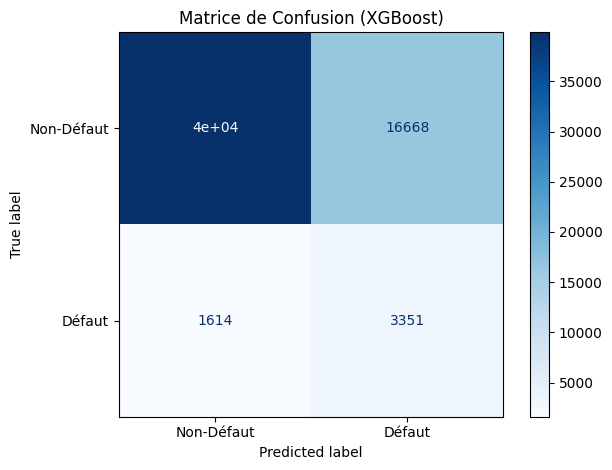

<Figure size 700x500 with 0 Axes>

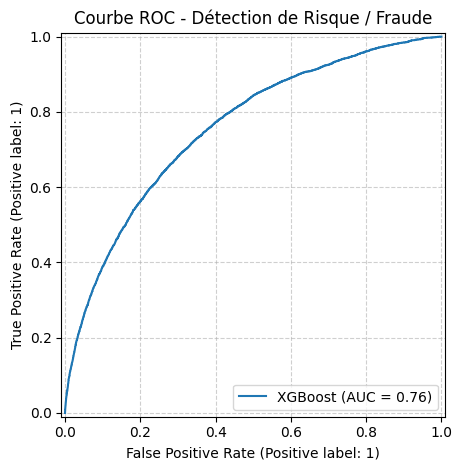

Graphiques enregistrés avec succès dans le dossier 'outputs/' !


In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# 1. Créer la Matrice de Confusion
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=['Non-Défaut', 'Défaut'],
    cmap='Blues'
)
plt.title('Matrice de Confusion (XGBoost)')
plt.tight_layout()
plt.savefig('/content/confusion_matrix_xgb.png', dpi=300)
plt.show()

# 2. Tracer la Courbe ROC
plt.figure(figsize=(7, 5))
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_xgb,
    name='XGBoost'
)
plt.title('Courbe ROC - Détection de Risque / Fraude')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('/content/roc_curve_xgb.png', dpi=300)
plt.show()

print("Graphiques enregistrés avec succès dans le dossier 'outputs/' !")

<Figure size 1000x600 with 0 Axes>

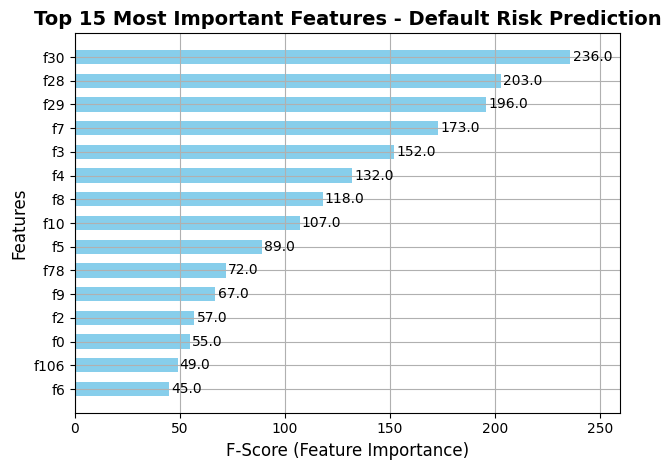

In [17]:
import matplotlib.pyplot as plt
import xgboost as xgb

# 1. Plot top 15 most important features from our trained XGBoost model
plt.figure(figsize=(10, 6))
xgb.plot_importance(xgb_model, max_num_features=15, height=0.6, color='skyblue')
plt.title('Top 15 Most Important Features - Default Risk Prediction', fontsize=14, fontweight='bold')
plt.xlabel('F-Score (Feature Importance)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()

# Save plot for your GitHub repository
plt.savefig('/content/feature_importance.png', dpi=300)
plt.show()

/tmp/ipykernel_765/17045156.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y, palette=['#2b5c8f', '#d9534f'])


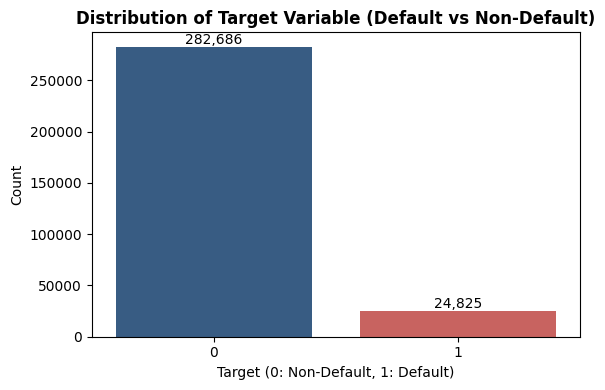

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Countplot of the Target variable
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y, palette=['#2b5c8f', '#d9534f'])
plt.title('Distribution of Target Variable (Default vs Non-Default)', fontsize=12, fontweight='bold')
plt.xlabel('Target (0: Non-Default, 1: Default)', fontsize=10)
plt.ylabel('Count', fontsize=10)

# Add data labels on top of the bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.savefig('/content/target_distribution.png', dpi=300)
plt.show()

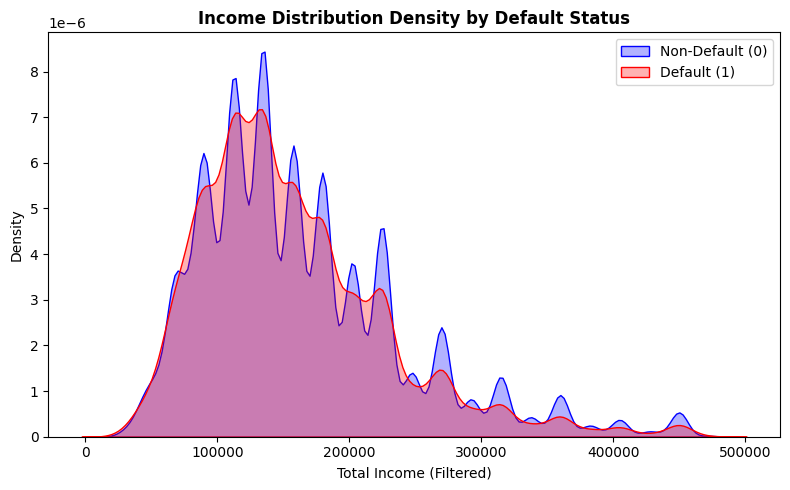

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create a temporary dataframe for plotting
plot_df = pd.DataFrame({
    'Income': df['AMT_INCOME_TOTAL'],
    'Target': df['TARGET']
})

# Filter out extreme outliers for a cleaner visualization (e.g., top 1%)
high_income_threshold = plot_df['Income'].quantile(0.99)
plot_df_filtered = plot_df[plot_df['Income'] <= high_income_threshold]

plt.figure(figsize=(8, 5))
sns.kdeplot(data=plot_df_filtered[plot_df_filtered['Target'] == 0]['Income'], label='Non-Default (0)', color='blue', fill=True, alpha=0.3)
sns.kdeplot(data=plot_df_filtered[plot_df_filtered['Target'] == 1]['Income'], label='Default (1)', color='red', fill=True, alpha=0.3)

plt.title('Income Distribution Density by Default Status', fontsize=12, fontweight='bold')
plt.xlabel('Total Income (Filtered)', fontsize=10)
plt.ylabel('Density', fontsize=10)
plt.legend()
plt.tight_layout()

plt.savefig('/content/income_distribution_kde.png', dpi=300)
plt.show()